# The Pokémon type chart

A few questions a player asks about the type chart:

- How many types are there, and what are they?
- What's the minimum sized set of attacking types that is super-effective against every type? A team has at most six Pokémon, so six would be a nice answer.
- Can a set of attacks also avoid being not very effective, or useless?
- Pokémon have one or two types. Which typings take the least damage, and which pair two types that disagree the most?
- How do typings, Pokémon and random teams score on attack and defense?
- What's really the best starter? What are the best Pokémon in the newest generation? What if we leave out legendaries and Megas?

The short answers, all exact for the Generation 6 chart and the Pokémon as of Generation 7: no six types cover the chart and ten sets of seven do, all with Fighting and Ground. Steel/Fairy takes the least damage, 53/4 summed over the 18 attacking types. Fighting/Ice is the most conflicted typing. Among final starters, Empoleon scores highest on the mix of base stats and typing defined below, and among Pokémon new in Generation 7 that are not legendary, Celesteela does. Those last answers depend on an arbitrary score, which the notebook defines before using.

The code is in `scoring.py` (scores) and `figures.py` (pictures), next to this notebook, so the tests can import it too. Nash equilibria of the chart, its rock-paper-scissors triangles and how much of it is a ranking are in `equilibrium.py` and `hodge.py`; the README has those results.

In [1]:
import random
from collections import Counter
from fractions import Fraction

import matplotlib.pyplot as plt
import pandas as pd

from pokemon import figures
from pokemon.scoring import CHART, RESISTED, SUPER, TYPES

## The chart

How many types are there, and what are they? `TYPES` lists them in the chart's usual order, and `CHART[a][d]` is the **multiplier** when a move of type `a` hits a Pokémon of type `d`: 2 (super-effective), 1/2 (not very effective), 0 (no effect) or 1. Multipliers are kept as fractions, so no sum below is rounded.

In [2]:
print(len(TYPES), "types:", " ".join(TYPES))

18 types: normal fire water electric grass ice fighting poison ground flying psychic bug rock ghost dragon dark steel fairy


Three entries every player knows, and the size of the table:

In [3]:
assert CHART["water"]["fire"] == 2 and CHART["fire"]["water"] == Fraction(1, 2)
assert CHART["normal"]["ghost"] == 0
assert all(len(CHART[a]) == 18 for a in TYPES)

Here is the whole chart. Blank cells are neutral (1); each row is one attacking type.

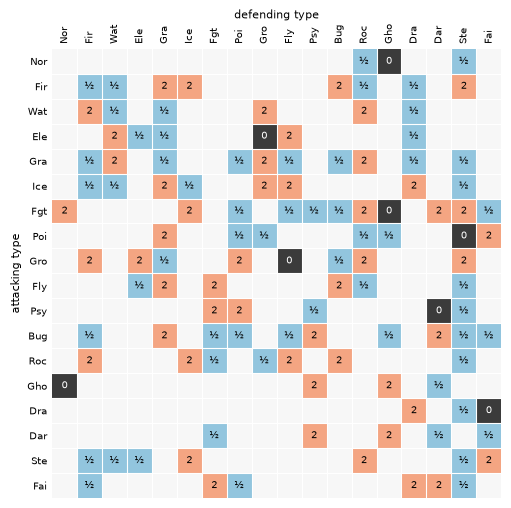

In [4]:
figures.draw_chart()
plt.show()

Two things stand out. The chart is mostly blank: 120 of its 324 cells are not neutral. And it is not symmetric: Fire beats Grass and Grass resists Fire, but Normal does nothing to Ghost while Ghost does nothing to Normal, and Dragon is super-effective against itself.

`hits(attackers, m)` is the set of single types that at least one of `attackers` hits with multiplier `m`. Bug, for example:

In [5]:
from pokemon.scoring import hits

print(sorted(hits(["bug"], SUPER)))
print(sorted(hits(["bug"], RESISTED)))
assert hits(["bug"], SUPER) == {"grass", "psychic", "dark"}
assert hits(["bug", "water"], SUPER) == {"grass", "psychic", "dark", "fire", "ground", "rock"}

['dark', 'grass', 'psychic']
['fairy', 'fighting', 'fire', 'flying', 'ghost', 'poison', 'steel']


## Covering every type

What's the minimum sized set of types that will be super-effective against all other types? Call such a set a **cover**. There are only $\binom{18}{k}$ sets of size $k$ (31,824 for $k = 7$), so `covers(k)` tries them all.

In [6]:
from pokemon.scoring import covers

assert covers(1) == [] and covers(2) == []
print("covers of six types:", covers(6))
seven = covers(7)
len(seven)

covers of six types: []


10

None of six, ten of seven. A second check that does not go through `hits`: read each of the ten sets against the chart directly, and confirm that dropping any one type from it leaves some type uncovered.

In [7]:
def covered(attackers):
    return all(any(CHART[a][d] == 2 for a in attackers) for d in TYPES)


assert all(covered(s) for s in seven)
assert not any(covered(s[:i] + s[i + 1 :]) for s in seven for i in range(7))
for s in seven:
    print(" ".join(s))

dark electric fighting flying ground ice poison
dark electric fighting flying ground ice steel
dark fairy fighting grass ground poison rock
dark fighting flying grass ground ice poison
dark fighting flying grass ground ice steel
electric fighting flying ghost ground ice poison
electric fighting flying ghost ground ice steel
fairy fighting ghost grass ground poison rock
fighting flying ghost grass ground ice poison
fighting flying ghost grass ground ice steel


Which types do the covers rely on?

In [8]:
Counter(t for s in seven for t in s).most_common()

[('fighting', 10),
 ('ground', 10),
 ('flying', 8),
 ('ice', 8),
 ('poison', 6),
 ('grass', 6),
 ('dark', 5),
 ('ghost', 5),
 ('electric', 4),
 ('steel', 4),
 ('fairy', 2),
 ('rock', 2)]

Fighting and Ground are in every cover: Fighting is the only type super-effective against Normal, and only Ground hits Electric hard. Here is one cover, with a mark wherever one of its types hits a defending type for double damage. Every column has a mark; some have three.

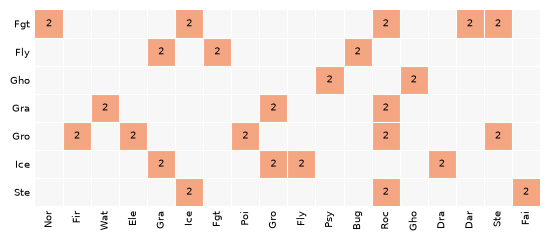

In [9]:
figures.draw_cover(seven[-1])
plt.show()

That's a pity, because in the standard games a team can have at most six members. Seven attacking types fit on six Pokémon only if some Pokémon carries moves of two types, which most can.

### A score for coverage

We can go further and ask for a set of attacking types that is also rarely resisted. Let's define a score, arbitrarily: two points for each type it hits super-effectively, minus one for each type that resists at least one of its types, minus two for each type immune to at least one of them. Ground alone, by hand: it hits Fire, Electric, Poison, Rock and Steel (10 points), is resisted by Grass and Bug (−2), and does nothing to Flying (−2).

In [10]:
from pokemon.scoring import best_coverage_scores, coverage_score

assert coverage_score(["ground"]) == 2 * 5 - 2 - 2 * 1
top, best = best_coverage_scores(largest=7)
print(f"best score {top}, reached by {len(best)} sets of 1 to 7 types; the smallest:")
for s in best:
    if len(s) == len(best[0]):
        print(" ", " ".join(s))

best score 18, reached by 16 sets of 1 to 7 types; the smallest:
  bug dark fairy grass ground rock
  dark fairy flying ground ice steel
  dark fairy ground ice rock steel
  fairy flying ghost ground ice steel


The best possible score is 36 (two points for each of 18 types), and nothing comes close: the best is 18, reached first by sets of six. More attacking types cover more, but each one brings its own resistances, so the penalty grows too. Every one of the 16 best sets includes Ground and Fairy.

## The Pokémon data

`pokemon_table` reads `pokeapi_forms.csv` (see the README for where it comes from) and keeps the forms that existed as of Generation 7, with the typings and base stats they had then. A **form** is one row: a species, or a Mega Evolution or other form of it. Typings are written in alphabetical order, so Steel/Fairy is `('fairy', 'steel')`.

In [11]:
from pokemon.scoring import by_typing, pokemon_table

table = pokemon_table(generation=7)
names = {row["name"] for row in table}
groups = by_typing(table)  # typing -> names of the forms with it
assert {"decidueye", "litten", "blissey", "toxapex"} <= names
assert sum(map(len, groups.values())) == len(table)
len(table), len(groups)

(955, 146)

In [12]:
pd.DataFrame(table).head()

,name,species,ndex,generation,typing,total,legendary,mega
0,bulbasaur,bulbasaur,1,1,"(grass, poison)",318,False,False
1,ivysaur,ivysaur,2,1,"(grass, poison)",405,False,False
2,venusaur,venusaur,3,1,"(grass, poison)",525,False,False
3,charmander,charmander,4,1,"(fire,)",309,False,False
4,charmeleon,charmeleon,5,1,"(fire,)",405,False,False


That is 955 forms with 146 different typings, out of the 18 + 153 = 171 possible. The older Kaggle table `Pokemon.csv` that the first version of this notebook used goes up to Generation 6, with 800 rows; it is kept for comparison.

In [13]:
kaggle = pd.read_csv("Pokemon.csv")
assert len(kaggle) == 800 and kaggle["#"].max() == 721
kaggle.sample(6, random_state=1)

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
8,6,CharizardMega Charizard Y,Fire,Flying,634,78,104,78,159,115,100,1,False
510,460,Abomasnow,Grass,Ice,494,90,92,75,92,85,60,4,False
175,161,Sentret,Normal,NaN,215,35,46,34,35,45,20,2,False
735,667,Litleo,Fire,Normal,369,62,50,58,73,54,72,6,False
242,224,Octillery,Water,NaN,480,75,105,75,105,75,45,2,False
764,694,Helioptile,Electric,Normal,289,44,38,33,61,43,70,6,False


Which Pokémon are Ghost/Grass? And four typings picked at random (seed 42):

In [14]:
print(sorted(groups[("ghost", "grass")]))
random.Random(42).sample(list(groups), 4)

['decidueye', 'dhelmise', 'gourgeist-average', 'gourgeist-large', 'gourgeist-small', 'gourgeist-super', 'phantump', 'pumpkaboo-average', 'pumpkaboo-large', 'pumpkaboo-small', 'pumpkaboo-super', 'trevenant']


[('fairy', 'psychic'),
 ('bug', 'poison'),
 ('fighting', 'psychic'),
 ('dark', 'grass')]

## Attack and defense of a typing

What does a Pokémon with two types deal, and what does it take? Some background first:

1. Is there a bonus for using a move of your own type? Yes: 1.5 times the damage ([same-type attack bonus](https://bulbapedia.bulbagarden.net/wiki/Same-type_attack_bonus)).
2. Are there moves of two types at once? Practically no; they would encourage using only the Pokémon that get double the bonus.
3. Is there a penalty for moves of other types? No.

Damage taken depends on the move's type, not the attacker's, so outgoing multipliers belong to single types. It is fairly safe to assume that a Pokémon can learn moves of each of its types, and the bonus gives it reason to use them. So the **outgoing** multiplier of a typing against a defending type is the best that one of its own types deals. We assume the Pokémon picks the move that does the most damage.

In [15]:
from pokemon.scoring import outgoing

ghost_ice = outgoing(("ghost", "ice"))
assert ghost_ice["normal"] == 1  # Ghost does nothing to Normal, but Ice does normal damage
assert ghost_ice["dragon"] == 2 and min(ghost_ice.values()) == 1  # nothing resists both
{t: str(m) for t, m in ghost_ice.items() if m != 1}

{'grass': '2',
 'ground': '2',
 'flying': '2',
 'psychic': '2',
 'ghost': '2',
 'dragon': '2'}

To see this working, let's find the Pokémon typings whose two types disagree the most. `conflict` sums, over the 18 defending types, the best multiplier one type deals minus the worst the other deals.

In [16]:
from pokemon.scoring import conflict

assert conflict(("water",)) == 0
assert conflict(("fire", "water")) == sum(abs(CHART["fire"][d] - CHART["water"][d]) for d in TYPES)
[(str(c), t) for c, t in sorted(((conflict(t), t) for t in groups), reverse=True)[:10]]

[('29/2', ('fighting', 'ice')),
 ('13', ('ground', 'ice')),
 ('13', ('fighting', 'flying')),
 ('25/2', ('bug', 'ground')),
 ('12', ('ground', 'poison')),
 ('12', ('fighting', 'rock')),
 ('12', ('fighting', 'ghost')),
 ('23/2', ('flying', 'ground')),
 ('23/2', ('fighting', 'psychic')),
 ('23/2', ('fighting', 'poison'))]

Fighting/Ice disagrees the most, with 29/2. Ground/Ice, second, shows why disagreement is good for attack: Ice hits Grass, Ground, Flying and Dragon, Ground hits Fire, Electric, Poison, Rock and Steel, and no type resists both.

In [17]:
{t: str(m) for t, m in outgoing(("ground", "ice")).items() if m != 1}

{'fire': '2',
 'electric': '2',
 'grass': '2',
 'poison': '2',
 'ground': '2',
 'flying': '2',
 'rock': '2',
 'dragon': '2',
 'steel': '2'}

How about **incoming**? The multiplier of a move against a Pokémon is the product of the multipliers for each of its types, so a move can be quadruple-effective. Taking the worst case is no good, because every type has some weakness; we take the sum over the 18 attacking types, which is 18 times the mean. A weighted mean, using how often each type of move is used, may be worth trying.

In [18]:
from pokemon.scoring import incoming

fairy_ice = incoming(("fairy", "ice"))
assert fairy_ice["steel"] == 2 * 2 and fairy_ice["dragon"] == 0
{t: str(m) for t, m in fairy_ice.items() if m != 1}

{'fire': '2',
 'ice': '1/2',
 'poison': '2',
 'bug': '1/2',
 'rock': '2',
 'dragon': '0',
 'dark': '1/2',
 'steel': '4'}

Which typings take the least, summed over all attacking types?

In [19]:
[(str(s), t) for s, t in sorted((sum(incoming(t).values()), t) for t in groups)[:10]]

[('53/4', ('fairy', 'steel')),
 ('27/2', ('flying', 'steel')),
 ('57/4', ('dragon', 'steel')),
 ('57/4', ('ghost', 'steel')),
 ('29/2', ('steel', 'water')),
 ('15', ('steel',)),
 ('31/2', ('dark', 'ghost')),
 ('31/2', ('fighting', 'steel')),
 ('63/4', ('bug', 'steel')),
 ('63/4', ('ground', 'steel'))]

Steel/Fairy takes 53/4 = 13.25, against 18 for a typing with no weaknesses or resistances, and Steel is in nine of the ten. Here are both rows of Steel/Fairy; the first is what it deals, the second what it takes:

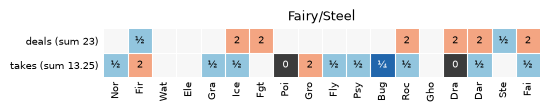

In [20]:
figures.draw_typing(("fairy", "steel"))
plt.show()

## Scoring typings

So how shall we score the values of `outgoing` and `incoming`? The number of entries matters too, but let's start with naïve sums: **attack** is the sum of the outgoing multipliers, **defense** minus the sum of the incoming ones. Then each is rescaled to run from 0 to 1 over the 146 typings that some Pokémon has. (The first version of this notebook standardized the sums and then rescaled them; standardizing is a change of scale and origin, so it made no difference.)

In [21]:
from pokemon.scoring import raw_scores, rescaled, typing_scores

assert rescaled([Fraction(1), Fraction(2), Fraction(5)]) == [0, Fraction(1, 4), 1]
assert raw_scores(("fairy", "steel"))[1] == Fraction(-53, 4)
scores = typing_scores(list(groups))  # typing -> (attack, defense), each in [0, 1]


def ranked(key, n=6):
    return pd.DataFrame(
        [
            (t, f"{float(a):.4f}", f"{float(d):.4f}", str(a + d))
            for t, (a, d) in sorted(scores.items(), key=lambda kv: -key(*kv[1]))[:n]
        ],
        columns=["typing", "attack", "defense", "sum (exact)"],
    )


ranked(lambda a, d: a)

,typing,attack,defense,sum (exact)
0,"(ground, ice)",1.0000,0.3529,23/17
1,"(fighting, ice)",1.0000,0.2745,65/51
2,"(ground, rock)",0.9091,0.1373,587/561
3,"(flying, ground)",0.9091,0.5882,280/187
4,"(fire, ground)",0.9091,0.5882,280/187
5,"(fighting, rock)",0.9091,0.3137,686/561


Best defense, and worst:

In [22]:
ranked(lambda a, d: d)

,typing,attack,defense,sum (exact)
0,"(fairy, steel)",0.6364,1.0000,18/11
1,"(flying, steel)",0.6364,0.9804,907/561
2,"(dragon, steel)",0.5000,0.9216,145/102
3,"(ghost, steel)",0.6364,0.9216,874/561
4,"(steel, water)",0.5909,0.9020,1675/1122
5,"(steel,)",0.2727,0.8627,637/561


In [23]:
ranked(lambda a, d: -d)

,typing,attack,defense,sum (exact)
0,"(ice, rock)",0.7727,0.0000,17/22
1,"(bug, grass)",0.5455,0.0784,350/561
2,"(grass, ice)",0.6364,0.0784,401/561
3,"(ground, rock)",0.9091,0.1373,587/561
4,"(grass, psychic)",0.5909,0.1569,839/1122
5,"(dark, ice)",0.7273,0.1961,518/561


Ground/Ice and Fighting/Ice attack best, Steel/Fairy defends best, and Ice/Rock defends worst. Which Pokémon are Ground/Ice?

In [24]:
sorted(groups[("ground", "ice")])

['mamoswine', 'piloswine', 'swinub']

Adding the two scores ranks the typings overall. To say where a typing stands we use its **percentile rank**: its rank from the bottom (the mean rank, if several typings tie with it) as a share of all the typings, in percent. `percentile` does that exactly, and agrees with scipy's `percentileofscore`:

In [25]:
from scipy.stats import percentileofscore

from pokemon.scoring import percentile

assert percentile([1, 2, 3, 4], 3) == 75  # third of four
assert percentile([1, 2, 2, 4], 2) == 62.5  # ranks 2 and 3 tie: 2.5 of 4
sums = [a + d for a, d in scores.values()]
assert all(
    abs(percentile(sums, s) - percentileofscore([float(x) for x in sums], float(s))) < 1e-9
    for s in sums
)
ranked(lambda a, d: a + d, n=10)

,typing,attack,defense,sum (exact)
0,"(fairy, steel)",0.6364,1.0000,18/11
1,"(ground, steel)",0.8182,0.8039,910/561
2,"(flying, steel)",0.6364,0.9804,907/561
3,"(ghost, steel)",0.6364,0.9216,874/561
4,"(fighting, steel)",0.7273,0.8235,290/187
5,"(flying, ground)",0.9091,0.5882,280/187
6,"(fire, ground)",0.9091,0.5882,280/187
7,"(steel, water)",0.5909,0.9020,1675/1122
8,"(bug, steel)",0.6364,0.8039,808/561
9,"(fairy, water)",0.7273,0.7059,268/187


In [26]:
percentile(sums, sum(scores[("normal",)]))

2.0547945205479454

Normal is near the bottom, at the 2nd percentile: it hits nothing super-effectively. Every typing on one picture, with the best and worst named:

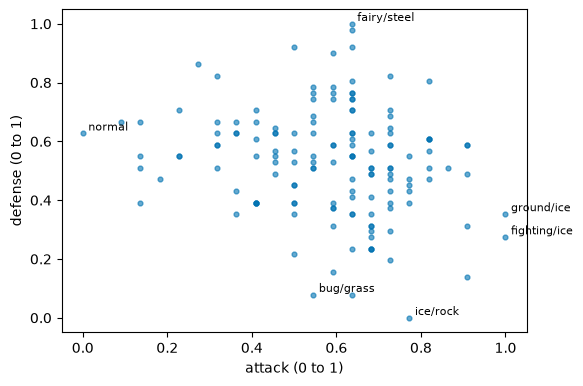

In [27]:
fig, ax = plt.subplots(figsize=(6, 4.2))
xy = {t: (float(a), float(d)) for t, (a, d) in scores.items()}
ax.scatter(*zip(*xy.values(), strict=True), s=12, color="#0072B2", alpha=0.6)
for t in [
    ("fairy", "steel"),
    ("ground", "ice"),
    ("fighting", "ice"),
    ("ice", "rock"),
    ("normal",),
    ("bug", "grass"),
]:
    ax.annotate("/".join(t), xy[t], fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("attack (0 to 1)")
ax.set_ylabel("defense (0 to 1)")
plt.show()

The trade-off between the two is weak (their correlation over the 146 typings is −0.20): the best typings for defense are average for attack, and the cloud is wide in both directions.

## Scoring Pokémon

A Pokémon is more than its typing: base stats matter at least as much. Its **stat percentile** is where its base-stat total ranks among the 955 forms, and its **cover percentile** where its typing's attack plus defense ranks among the 146 typings. Blissey has a high total and the Normal typing:

In [28]:
from pokemon.scoring import pokemon_scores

poke = pokemon_scores(table, scores)  # name -> (stat percentile, cover percentile)
totals = [row["total"] for row in table]
blissey = next(row["total"] for row in table if row["name"] == "blissey")
below, tied = sum(t < blissey for t in totals), sum(t == blissey for t in totals)
assert poke["blissey"][0] == 100 * (below + (tied + 1) / 2) / len(totals)
poke["blissey"], poke["toxapex"]

((83.19371727748691, 2.0547945205479454),
 (66.91099476439791, 81.16438356164383))

Blissey's total of 540 is at the 83rd percentile, and Toxapex's typing at the 81st. Summing the two percentiles and ranking again gives one number per Pokémon; Toxapex's is the 90th percentile:

In [29]:
combined = {name: s + c for name, (s, c) in poke.items()}
percentile(list(combined.values()), combined["toxapex"])

90.15706806282722

What are the best Pokémon by this score? The first version of this notebook left out Megas and weighted the typing twice:

In [30]:
rows = {row["name"]: row for row in table}


def best(keep, key=lambda name: combined[name], n=10):
    names = sorted((name for name in poke if keep(rows[name])), key=lambda name: (-key(name), name))
    return pd.DataFrame(
        [(name, f"{poke[name][0]:.1f}", f"{poke[name][1]:.1f}") for name in names[:n]],
        columns=["form", "stat percentile", "cover percentile"],
    )


best(lambda r: not r["mega"], key=lambda name: poke[name][0] + 2 * poke[name][1])

,form,stat percentile,cover percentile
0,groudon-primal,99.6,96.2
1,magearna,91.8,100.0
2,magearna-original,91.8,100.0
3,landorus-incarnate,91.8,96.2
4,landorus-therian,91.8,96.2
5,celesteela,85.6,98.6
6,cobalion,87.7,97.3
7,genesect,91.8,94.5
8,dialga,97.4,91.1
9,marshadow,91.8,92.5


Primal Groudon leads, and the list is mostly legendary. Weighting the two equally from here on, and leaving out legendaries, mythical Pokémon and Megas:

In [31]:
best(lambda r: not r["legendary"] and not r["mega"])

,form,stat percentile,cover percentile
0,celesteela,85.6,98.6
1,blacephalon,85.6,90.4
2,lucario,78.2,97.3
3,empoleon,80.2,95.2
4,metagross,91.8,83.6
5,aegislash-blade,76.4,97.9
6,aegislash-shield,76.4,97.9
7,primarina,80.2,93.8
8,steelix,73.8,99.3
9,excadrill,73.1,99.3


Celesteela and Blacephalon are Ultra Beasts, which the data does not count as legendary. Then Lucario, Empoleon, Metagross and Aegislash, all part Steel.

What's really the best starter? `starter` picks out the 21 starters of Generations 1 to 7 by their National Pokédex numbers; their last evolutions, without Megas:

In [32]:
from pokemon.scoring import starter

assert [n for n in range(1, 30) if starter(n, final=True)] == [3, 6, 9]
assert sum(starter(row["ndex"]) for row in table if row["name"] == row["species"]) == 63
best(lambda r: starter(r["ndex"], final=True) and not r["mega"], n=8)

,form,stat percentile,cover percentile
0,empoleon,80.2,95.2
1,primarina,80.2,93.8
2,infernape,81.5,87.7
3,blaziken,80.2,87.7
4,emboar,79.2,87.7
5,incineroar,80.2,82.9
6,swampert,82.2,75.3
7,greninja-ash,95.9,60.3


Empoleon (Water/Steel), then Primarina, Infernape and Blaziken. Ash-Greninja is a form of Greninja, not a separate starter; its base stats are higher. And the best of the newest generation in this data, Generation 7, without legendaries:

In [33]:
best(lambda r: r["generation"] == 7 and not r["legendary"], n=8)

,form,stat percentile,cover percentile
0,celesteela,85.6,98.6
1,blacephalon,85.6,90.4
2,primarina,80.2,93.8
3,incineroar,80.2,82.9
4,kartana,85.6,76.0
5,golisopod,80.2,77.1
6,greninja-ash,95.9,60.3
7,palossand,58.6,92.5


All of these depend on adding two percentiles, which is a choice, not a fact about the games. The picture shows both percentiles for every form, split into Megas (of legendaries too), other legendary or mythical forms, and the rest:

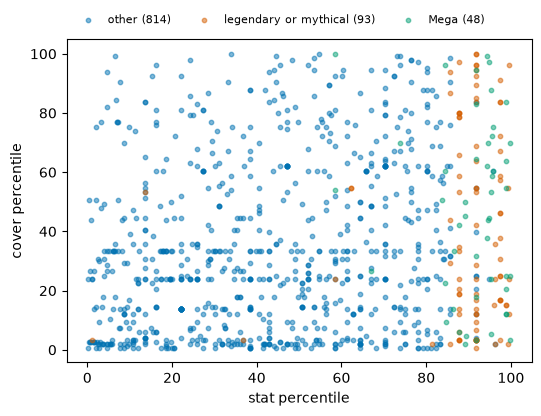

In [34]:
fig, ax = plt.subplots(figsize=(6, 4.2))
groups_of = {
    "other": lambda r: not r["legendary"] and not r["mega"],
    "legendary or mythical": lambda r: r["legendary"] and not r["mega"],
    "Mega": lambda r: r["mega"],
}
for (label, keep), color in zip(groups_of.items(), ["#0072B2", "#D55E00", "#009E73"], strict=True):
    pts = [poke[r["name"]] for r in table if keep(r)]
    ax.scatter(*zip(*pts, strict=True), s=10, alpha=0.5, color=color, label=f"{label} ({len(pts)})")
ax.set_xlabel("stat percentile")
ax.set_ylabel("cover percentile")
ax.legend(fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.01), ncols=3, frameon=False)
plt.show()

Legendaries and Megas sit at the right, by their base stats, across the full range of typings. The cover percentile comes in stripes, because many forms share a typing.

## Random teams

Finally, teams. Draw 10,000 teams of six different typings uniformly from the 146 (seed 42), and give each team the mean attack and defense of its typings, rescaled as before:

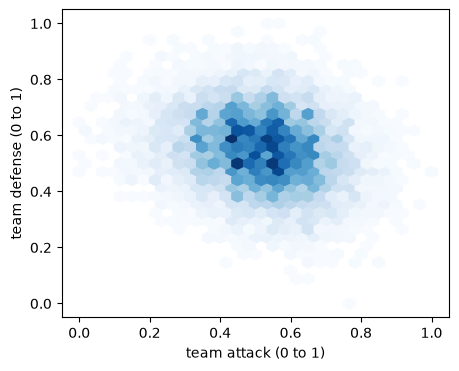

In [35]:
from pokemon.scoring import random_teams

teams = random_teams(list(groups), teams=10_000, seed=42)
attack, defense = zip(*teams, strict=True)
attack, defense = rescaled(attack), rescaled(defense)
fig, ax = plt.subplots(figsize=(5, 4))
ax.hexbin(
    [float(a) for a in attack], [float(d) for d in defense], gridsize=30, cmap="Blues", mincnt=1
)
ax.set_xlabel("team attack (0 to 1)")
ax.set_ylabel("team defense (0 to 1)")
plt.show()

A random team is middling at both. The numbers before rescaling show how much averaging over six typings narrows the spread:

In [36]:
from statistics import correlation, pstdev

singles = [raw_scores(t) for t in groups]
for name, values in (("typings", singles), ("teams", teams)):
    a, d = (list(map(float, v)) for v in zip(*values, strict=True))
    print(
        f"{name:8} standard deviation: attack {pstdev(a):.2f}, defense {pstdev(d):.2f}; correlation {correlation(a, d):+.2f}"
    )

typings  standard deviation: attack 2.08, defense 2.34; correlation -0.20
teams    standard deviation: attack 0.83, defense 0.94; correlation -0.20


The spread shrinks by a factor of about 2.5, close to the $\sqrt 6 \approx 2.45$ of an average of six independent draws, and the weak trade-off between attack and defense carries over. A team that is good at both needs to be chosen, which is what the covers above and the equilibria in `equilibrium.py` are about.

## Questions left open

- **Better scores.** The sums treat every type as equally likely to be met. Weighting by how often each type is used, as the README's comparison with Showdown usage does for the equilibrium, would change the rankings.
- **Teams.** The best team of six for coverage and defense together, with real movesets rather than one move per type.
- **Other generations.** `chart(g)` and `pokemon_table(g)` give every generation's chart and Pokémon, so each question here can be asked of Generation 1 or 9.